# CNN vs Random Forest

Side-by-side comparison of the two genre classifiers on the **same holdout set**: both models were split with
`StratifiedGroupKFold(random_state=42)` by song, so they are tested on the same 200 songs (2,000 three-second fragments).

| | Random Forest | CNN |
|---|---|---|
| Input | 57 handcrafted audio features per fragment (`features_3_sec.csv`) | Mel spectrogram image per fragment |
| Model | `models/random_forest.json` | `models/cnn.json` |

Both models are loaded from their JSON files and run here with NumPy only (no PyTorch or GPU needed).

In [1]:
import sys
import importlib.util
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score, log_loss, precision_recall_fscore_support

NOTEBOOK_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(p for p in [NOTEBOOK_DIR, *NOTEBOOK_DIR.parents] if (p / "pyproject.toml").is_file())
RF_MODULE_PATH = PROJECT_ROOT / "random_forest" / "random_forest_genres.py"
RF_MODEL_PATH = PROJECT_ROOT / "models" / "random_forest.json"
CNN_MODULE_PATH = PROJECT_ROOT / "cnn" / "cnn_genres_classifier.py"
CNN_MODEL_PATH = PROJECT_ROOT / "models" / "cnn.json"
CHUNK_SIZE = 128


def load_module(name, path):
    spec = importlib.util.spec_from_file_location(name, path)
    module = importlib.util.module_from_spec(spec)
    sys.modules[name] = module
    spec.loader.exec_module(module)
    return module


rf_module = load_module("random_forest_genres", RF_MODULE_PATH)
cnn_module = load_module("cnn_genres_classifier", CNN_MODULE_PATH)
with open(RF_MODEL_PATH, encoding="utf-8") as f:
    rf_results = json.load(f)
with open(CNN_MODEL_PATH, encoding="utf-8") as f:
    cnn_results = json.load(f)

assert rf_results["split"]["test_songs"] == cnn_results["split"]["test_songs"], "Models were tested on different songs"
labels = np.asarray(rf_results["model"]["classes"], dtype=object)
assert labels.tolist() == cnn_results["model"]["classes"], "Models use a different class order"

# Random forest: features CSV
rf_model = rf_module.RandomForestFromJSON(rf_results["model"])
features = pd.read_csv(PROJECT_ROOT / rf_results["metadata"]["data_path"])
id_parts = features["filename"].astype(str).str.extract(rf_results["config"]["song_id_pattern"])
features["song_id"] = id_parts[0].str.lower() + id_parts[1]
features = features[features["song_id"].isin(rf_results["split"]["test_songs"])]
features = features.sort_values("filename").reset_index(drop=True)
rf_proba = rf_model.predict_proba(features)

# CNN: spectrogram PNGs
paths = sorted((PROJECT_ROOT / cnn_results["metadata"]["data_path"]).rglob("*.png"))
images = pd.DataFrame({"path": paths, "filename": [p.stem for p in paths], "label": [p.parent.name for p in paths]})
id_parts = images["filename"].str.extract(cnn_results["config"]["song_id_pattern"])
images["song_id"] = id_parts[0].str.lower() + id_parts[1]
images = images[images["song_id"].isin(cnn_results["split"]["test_songs"])]
images = images.sort_values("filename").reset_index(drop=True)
cnn_proba = np.concatenate(
    [
        cnn_module.predict_proba(
            np.stack([cnn_module.load_spectrogram_png(p) for p in images["path"].iloc[start:start + CHUNK_SIZE]]),
            CNN_MODEL_PATH,
        )[1]
        for start in range(0, len(images), CHUNK_SIZE)
    ]
)

# One row per holdout fragment, aligned by filename
assert (features["filename"].astype(str).values == images["filename"].values).all(), "Fragments do not line up"
df = images[["filename", "song_id", "label", "path"]].copy()
df["rf_pred"] = labels[rf_proba.argmax(axis=1)]
df["cnn_pred"] = labels[cnn_proba.argmax(axis=1)]
df["rf_correct"] = df["rf_pred"] == df["label"]
df["cnn_correct"] = df["cnn_pred"] == df["label"]
probas = {"Random Forest": rf_proba, "CNN": cnn_proba}
preds = {"Random Forest": df["rf_pred"], "CNN": df["cnn_pred"]}

# Song level: average the fragment probabilities of each song
songs = df.groupby("song_id")["label"].first()
song_probas = {name: pd.DataFrame(p, columns=labels).groupby(df["song_id"].values).mean().loc[songs.index] for name, p in probas.items()}
song_preds = {name: p.idxmax(axis=1) for name, p in song_probas.items()}

print(f"Holdout fragments: {len(df)} | Songs: {len(songs)}")
print(f"Random Forest accuracy: {df['rf_correct'].mean():.4f} | Stored: {rf_results['holdout']['accuracy']:.4f}")
print(f"CNN accuracy:           {df['cnn_correct'].mean():.4f} | Stored: {cnn_results['holdout']['accuracy']:.4f}")

Holdout fragments: 2000 | Songs: 200
Random Forest accuracy: 0.7135 | Stored: 0.7135
CNN accuracy:           0.7430 | Stored: 0.7430


In [2]:
# Chart style. One fixed color per model in every chart: Random Forest = blue, CNN = orange.
COLORS = {"Random Forest": "#2a78d6", "CNN": "#eb6834"}
NEUTRAL = {"both right": "#c3c2b7", "both wrong": "#52514e"}
INK, INK_SECONDARY, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update(
    {
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": AXIS,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "xtick.labelcolor": INK_SECONDARY,
        "ytick.labelcolor": INK_SECONDARY,
        "legend.frameon": False,
        "lines.linewidth": 2,
        "font.size": 10,
    }
)

## Overall

Fragment accuracy scores every 3-second clip on its own. Song accuracy averages the clip probabilities of each song
first, which is how the jazz filter would decide on a full track.

,Random Forest,CNN
Fragment accuracy,0.7135,0.743
Song accuracy,0.78,0.81
Macro F1 (fragments),0.711569,0.74166
Log loss (fragments),0.936811,0.845299
Model size,"500 trees, 1,133,914 nodes","172,362 parameters"
Model file (MB),47.0,3.5


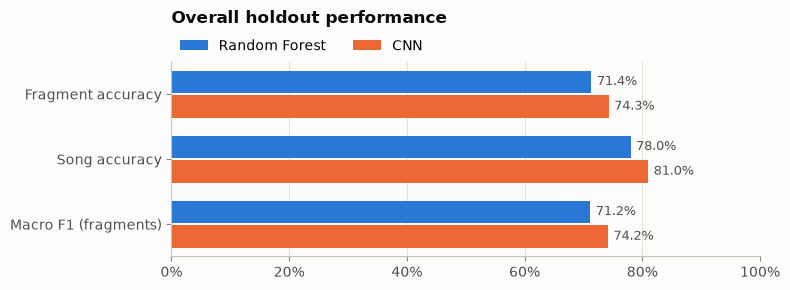

In [3]:
def model_size(name):
    if name == "Random Forest":
        trees = rf_results["model"]["trees"]
        return f"{len(trees)} trees, {sum(len(t['children_left']) for t in trees):,} nodes"
    return f"{cnn_results['architecture']['total_parameters']:,} parameters"


summary = pd.DataFrame(
    {
        name: {
            "Fragment accuracy": accuracy_score(df["label"], preds[name]),
            "Song accuracy": accuracy_score(songs, song_preds[name]),
            "Macro F1 (fragments)": f1_score(df["label"], preds[name], average="macro"),
            "Log loss (fragments)": log_loss(df["label"], probas[name], labels=labels),
            "Model size": model_size(name),
            "Model file (MB)": round((RF_MODEL_PATH if name == "Random Forest" else CNN_MODEL_PATH).stat().st_size / 1024 ** 2, 1),
        }
        for name in probas
    }
)
display(summary)

fig, ax = plt.subplots(figsize=(8, 3))
metrics_to_plot = ["Fragment accuracy", "Song accuracy", "Macro F1 (fragments)"]
y = np.arange(len(metrics_to_plot))
height = 0.38
for offset, name in zip([-height / 2, height / 2], probas):
    values = summary.loc[metrics_to_plot, name].astype(float).values
    bars = ax.barh(y + offset, values, height=height - 0.04, color=COLORS[name], label=name)
    ax.bar_label(bars, labels=[f"{v:.1%}" for v in values], padding=4, color=INK_SECONDARY, fontsize=9)
ax.set_yticks(y, metrics_to_plot)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.set_title("Overall holdout performance", pad=28)
ax.legend(ncols=2, loc="lower left", bbox_to_anchor=(0, 1.0), borderaxespad=0.2)
plt.tight_layout()
plt.show()

## Per genre

Precision: of the clips a model labels as a genre, how many really are that genre. Recall: of the clips of a genre,
how many the model finds.

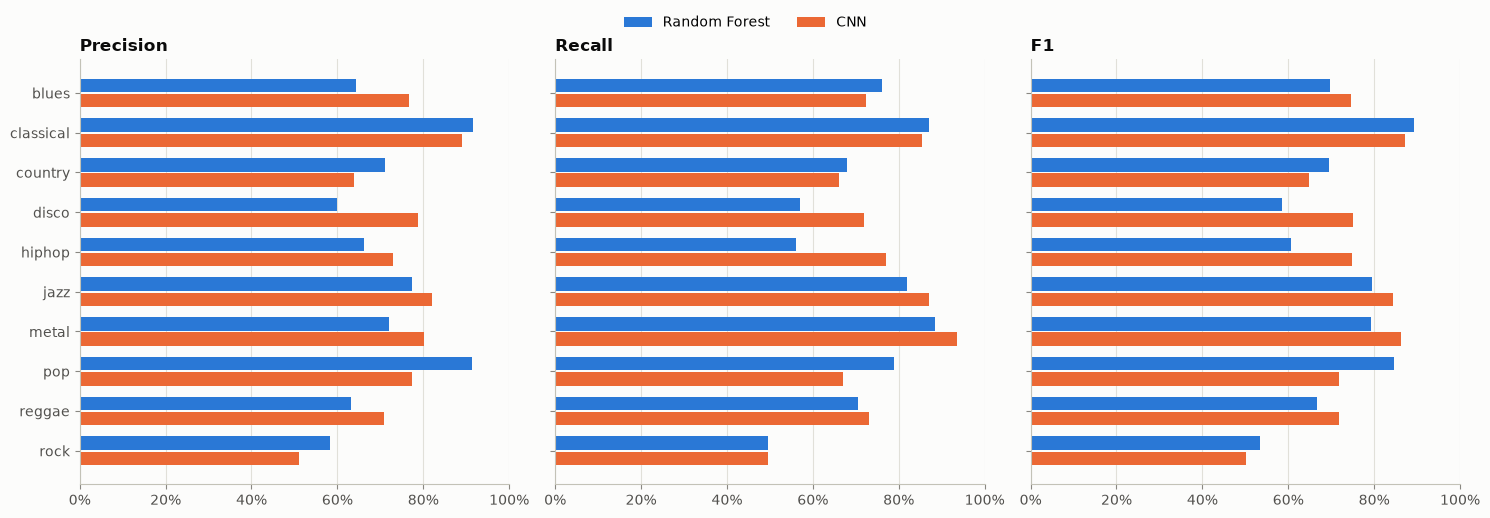

Random Forest                     CNN               CNN - RF
              precision recall     f1 precision recall     f1       f1
disco             0.600  0.570  0.585     0.787  0.720  0.752    0.167
hiphop            0.663  0.560  0.607     0.730  0.770  0.749    0.142
metal             0.720  0.885  0.794     0.803  0.935  0.864    0.070
reggae            0.632  0.705  0.667     0.709  0.730  0.719    0.053
jazz              0.774  0.820  0.796     0.821  0.870  0.845    0.049
blues             0.644  0.760  0.697     0.767  0.725  0.746    0.048
classical         0.916  0.870  0.892     0.891  0.855  0.872   -0.020
rock              0.582  0.495  0.535     0.510  0.495  0.503   -0.033
country           0.712  0.680  0.696     0.638  0.660  0.649   -0.047
pop               0.913  0.790  0.847     0.775  0.670  0.718   -0.129

In [4]:
per_genre = {}
for name in probas:
    precision, recall, f1, _ = precision_recall_fscore_support(df["label"], preds[name], labels=labels, zero_division=0)
    per_genre[name] = pd.DataFrame({"precision": precision, "recall": recall, "f1": f1}, index=labels)

fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
y = np.arange(len(labels))
for ax, metric in zip(axes, ["precision", "recall", "f1"]):
    for offset, name in zip([-height / 2, height / 2], probas):
        ax.barh(y + offset, per_genre[name][metric], height=height - 0.04, color=COLORS[name], label=name)
    ax.set_title(metric.capitalize() if metric != "f1" else "F1")
    ax.set_xlim(0, 1)
    ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(y, labels)
axes[0].invert_yaxis()
fig.legend(*axes[0].get_legend_handles_labels(), ncols=2, loc="upper center", bbox_to_anchor=(0.5, 1.04))
plt.tight_layout()
plt.show()

comparison = pd.concat({name: table for name, table in per_genre.items()}, axis=1)
comparison[("CNN - RF", "f1")] = comparison[("CNN", "f1")] - comparison[("Random Forest", "f1")]
display(comparison.sort_values(("CNN - RF", "f1"), ascending=False).round(3))

## Confusion matrices

Rows are the true genre and each row sums to 100%. The third panel subtracts the two: orange cells are where the CNN
puts more clips than the random forest, blue cells where the random forest does. On the diagonal, orange means the CNN
gets that genre right more often; off the diagonal, orange means the CNN makes that mistake more often.

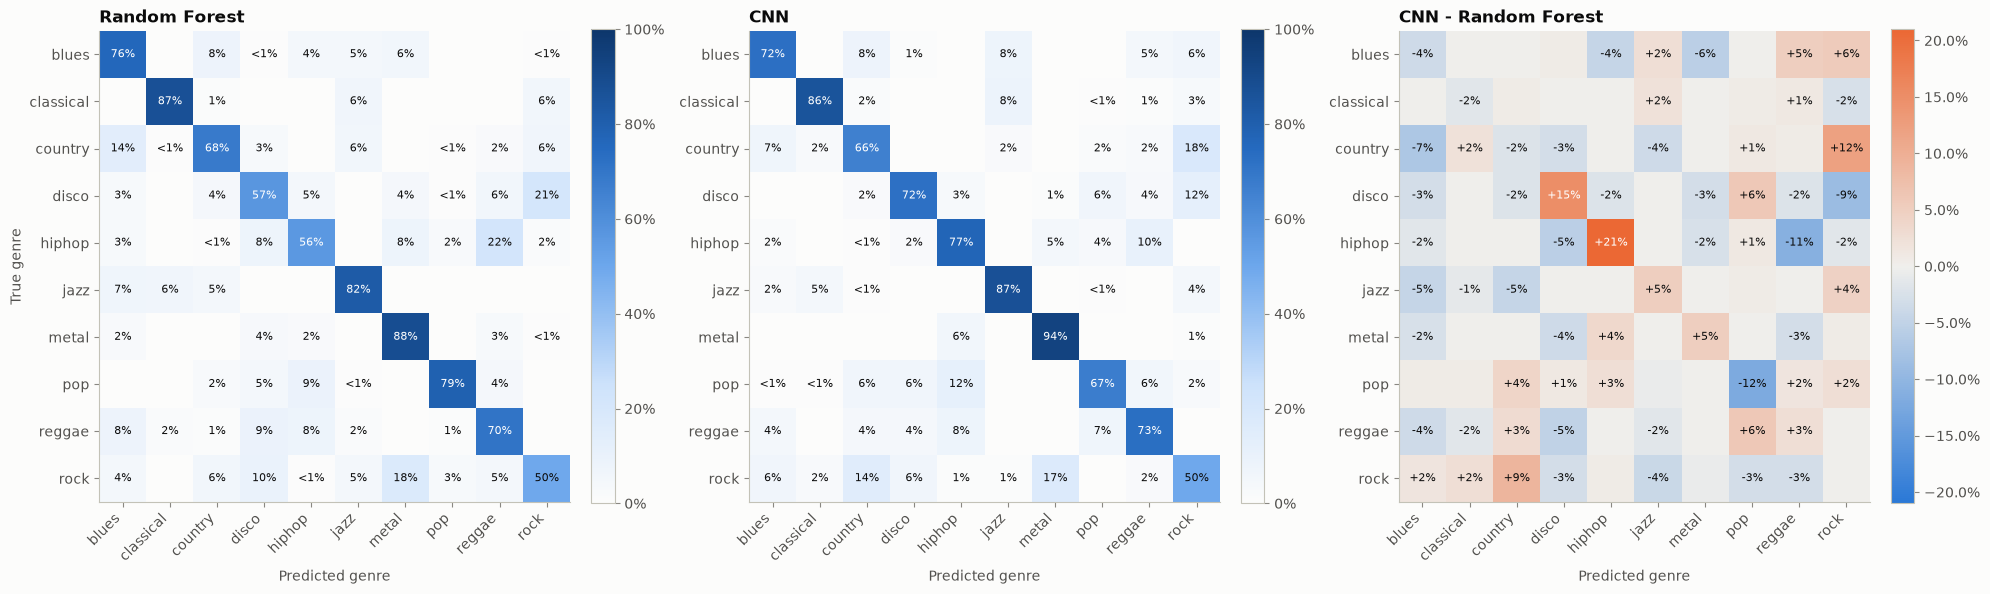

In [5]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.metrics import confusion_matrix

sequential = LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#cde2fb", "#6da7ec", "#256abf", "#0d366b"])
diverging = LinearSegmentedColormap.from_list("div", [COLORS["Random Forest"], "#f0efec", COLORS["CNN"]])

matrices = {name: confusion_matrix(df["label"], preds[name], labels=labels, normalize="true") for name in probas}
matrices["CNN - Random Forest"] = matrices["CNN"] - matrices["Random Forest"]

fig, axes = plt.subplots(1, 3, figsize=(20, 6.5))
for ax, (name, matrix) in zip(axes, matrices.items()):
    if name == "CNN - Random Forest":
        limit = np.abs(matrix).max()
        image = ax.imshow(matrix, cmap=diverging, norm=TwoSlopeNorm(0, -limit, limit))
        text = lambda v: f"{v:+.0%}" if abs(v) >= 0.0075 else ""  # hide single-clip (0.5%) differences
    else:
        image = ax.imshow(matrix, cmap=sequential, vmin=0, vmax=1)
        text = lambda v: "" if v == 0 else ("<1%" if v < 0.0075 else f"{v:.0%}")
    for i in range(len(labels)):
        for j in range(len(labels)):
            value = matrix[i, j]
            dark_cell = (name != "CNN - Random Forest" and value > 0.55) or (name == "CNN - Random Forest" and abs(value) > 0.6 * limit)
            ax.text(j, i, text(value), ha="center", va="center", fontsize=8, color="#ffffff" if dark_cell else INK)
    ax.set_xticks(range(len(labels)), labels, rotation=45, ha="right")
    ax.set_yticks(range(len(labels)), labels)
    ax.grid(False)
    ax.set_title(name)
    ax.set_xlabel("Predicted genre")
    fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, format=plt.matplotlib.ticker.PercentFormatter(1.0))
axes[0].set_ylabel("True genre")
plt.tight_layout()
plt.show()

## Where the models agree and disagree

Every holdout clip falls into one of four groups. If the models made the same mistakes, combining them would not help;
the more "only one right" clips there are, the more they complement each other.

McNemar's test checks whether the accuracy difference is larger than chance, using only the clips where exactly one
model is right.

,clips,share
both right,1180,0.590
only CNN right,306,0.153
only Random Forest right,247,0.124
both wrong,267,0.134


McNemar exact test: CNN-only 306 vs RF-only 247 clips, p = 0.014


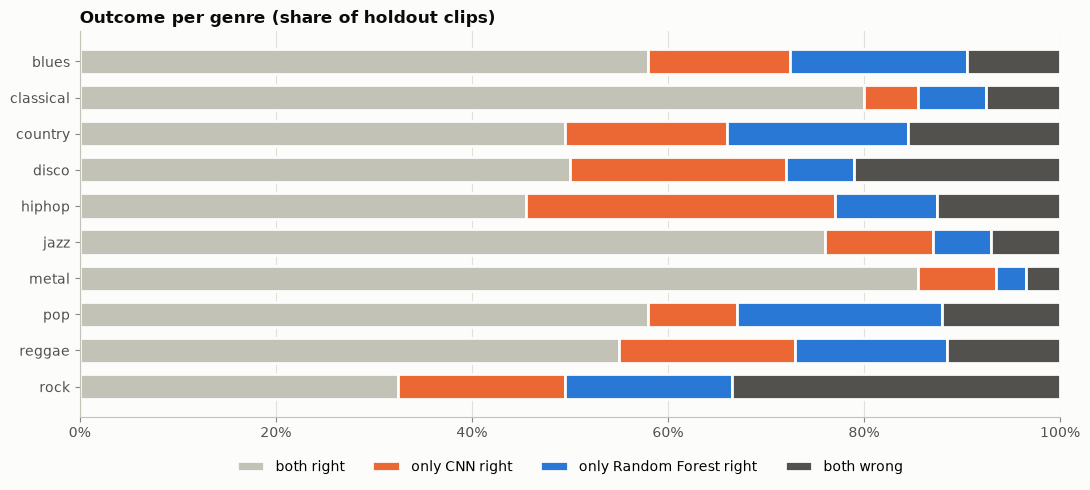

In [6]:
from scipy.stats import binomtest

outcome = np.select(
    [df["rf_correct"] & df["cnn_correct"], df["cnn_correct"], df["rf_correct"]],
    ["both right", "only CNN right", "only Random Forest right"],
    "both wrong",
)
order = ["both right", "only CNN right", "only Random Forest right", "both wrong"]
outcome_colors = [NEUTRAL["both right"], COLORS["CNN"], COLORS["Random Forest"], NEUTRAL["both wrong"]]
counts = pd.Series(outcome).value_counts().reindex(order, fill_value=0)
display(pd.DataFrame({"clips": counts, "share": (counts / len(df)).round(3)}))

only_cnn, only_rf = counts["only CNN right"], counts["only Random Forest right"]
p_value = binomtest(int(only_cnn), int(only_cnn + only_rf), 0.5).pvalue
print(f"McNemar exact test: CNN-only {only_cnn} vs RF-only {only_rf} clips, p = {p_value:.2g}")

shares = pd.crosstab(df["label"], outcome, normalize="index").reindex(columns=order, fill_value=0).loc[labels]
fig, ax = plt.subplots(figsize=(11, 5))
left = np.zeros(len(shares))
for column, color in zip(order, outcome_colors):
    ax.barh(shares.index, shares[column], left=left, color=color, edgecolor="#fcfcfb", linewidth=2, label=column, height=0.7)
    left += shares[column].values
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.grid(axis="y", visible=False)
ax.set_title("Outcome per genre (share of holdout clips)")
ax.legend(ncols=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.show()

## Confidence

The confidence of a prediction is the probability the model gives to its top genre. A well-calibrated model is right
about 70% of the time when it says 70%; points under the dashed line mean overconfidence, points above it
underconfidence.

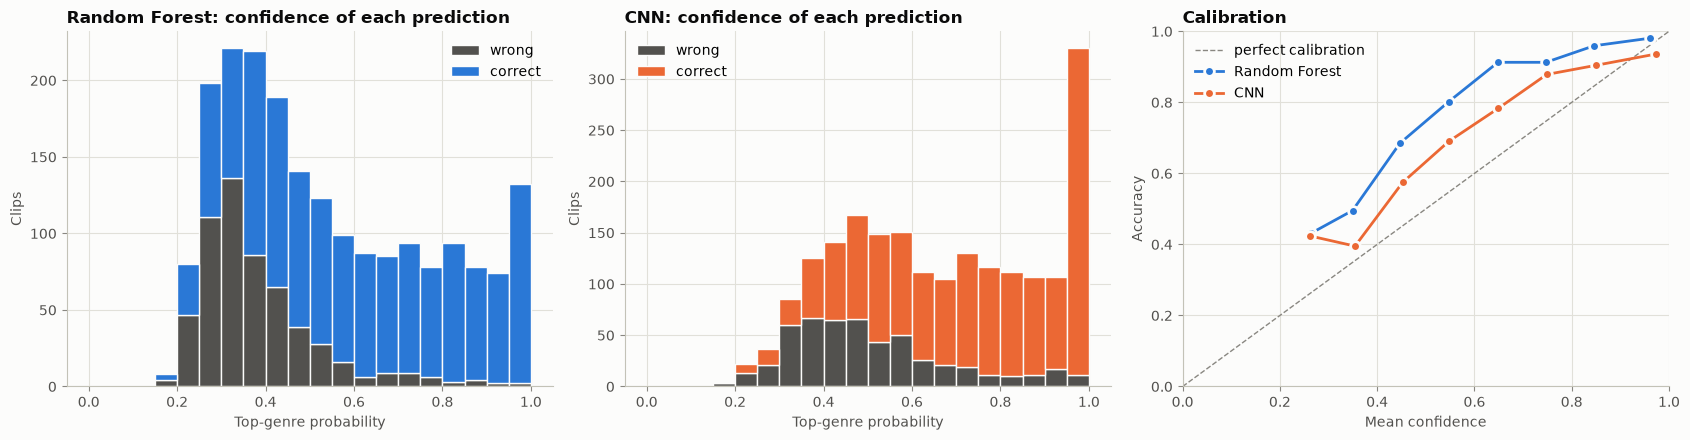

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
bins = np.linspace(0, 1, 21)
for ax, name in zip(axes[:2], probas):
    confidence = probas[name].max(axis=1)
    correct = preds[name].values == df["label"].values
    ax.hist([confidence[~correct], confidence[correct]], bins=bins, stacked=True, color=[NEUTRAL["both wrong"], COLORS[name]],
            label=["wrong", "correct"], edgecolor="#fcfcfb", linewidth=1)
    ax.set_title(f"{name}: confidence of each prediction")
    ax.set_xlabel("Top-genre probability")
    ax.set_ylabel("Clips")
    ax.legend()

ax = axes[2]
ax.plot([0, 1], [0, 1], linestyle="--", color=MUTED, linewidth=1, label="perfect calibration")
for name in probas:
    confidence = probas[name].max(axis=1)
    correct = preds[name].values == df["label"].values
    bin_index = np.clip(np.digitize(confidence, np.linspace(0, 1, 11)) - 1, 0, 9)
    calibration = pd.DataFrame({"bin": bin_index, "confidence": confidence, "correct": correct}).groupby("bin").agg(
        confidence=("confidence", "mean"), accuracy=("correct", "mean"), clips=("correct", "size")
    )
    calibration = calibration[calibration["clips"] >= 10]
    ax.plot(calibration["confidence"], calibration["accuracy"], color=COLORS[name], marker="o", markersize=7,
            markeredgecolor="#fcfcfb", markeredgewidth=2, label=name)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_title("Calibration")
ax.set_xlabel("Mean confidence")
ax.set_ylabel("Accuracy")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

## The jazz filter

The project's real task is binary: play a song if it is jazz, skip it otherwise. Here each model's jazz probability is
used on its own. The ROC curve shows every possible threshold; the table uses the rule the classifier applies
(skip unless jazz is the most likely genre), at song level.

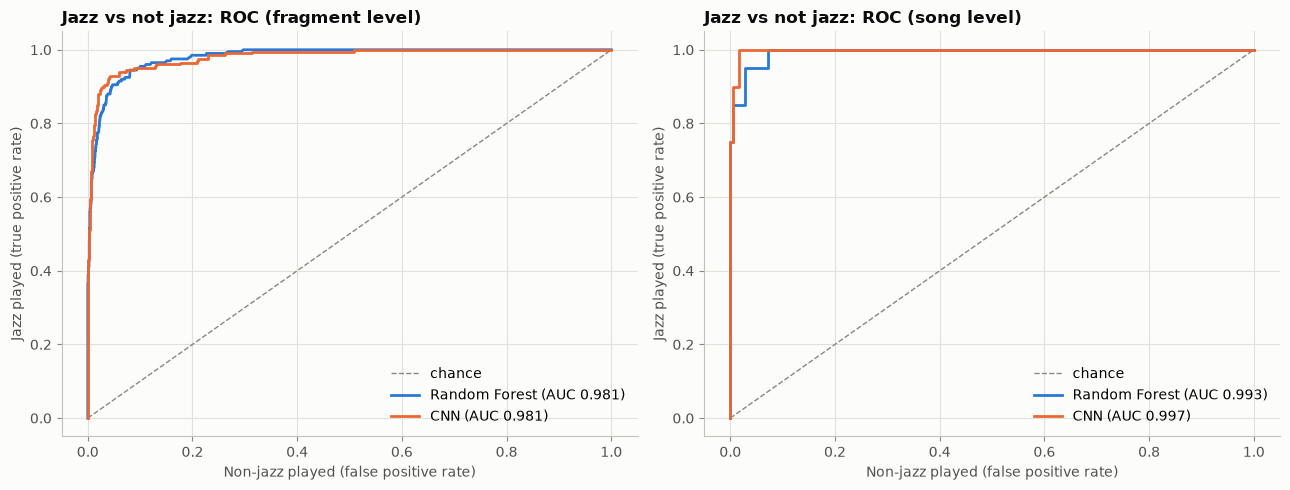

,Random Forest,CNN
Jazz songs played,17 / 20,18 / 20
Jazz songs wrongly skipped,3,2
Non-jazz songs wrongly played,3,3
Played songs that are jazz (precision),0.85,0.857


In [8]:
from sklearn.metrics import roc_auc_score, roc_curve

jazz = list(labels).index("jazz")
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, level in zip(axes, ["fragment", "song"]):
    ax.plot([0, 1], [0, 1], linestyle="--", color=MUTED, linewidth=1, label="chance")
    for name in probas:
        if level == "fragment":
            truth, score = df["label"].values == "jazz", probas[name][:, jazz]
        else:
            truth, score = songs.values == "jazz", song_probas[name]["jazz"].values
        fpr, tpr, _ = roc_curve(truth, score)
        ax.plot(fpr, tpr, color=COLORS[name], label=f"{name} (AUC {roc_auc_score(truth, score):.3f})")
    ax.set_title(f"Jazz vs not jazz: ROC ({level} level)")
    ax.set_xlabel("Non-jazz played (false positive rate)")
    ax.set_ylabel("Jazz played (true positive rate)")
    ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

rows = {}
for name in probas:
    played = song_preds[name].values == "jazz"
    is_jazz = songs.values == "jazz"
    rows[name] = {
        "Jazz songs played": f"{(played & is_jazz).sum()} / {is_jazz.sum()}",
        "Jazz songs wrongly skipped": int((~played & is_jazz).sum()),
        "Non-jazz songs wrongly played": int((played & ~is_jazz).sum()),
        "Played songs that are jazz (precision)": round((played & is_jazz).sum() / max(played.sum(), 1), 3),
    }
display(pd.DataFrame(rows))

## Combining the models

Because the models make partly different mistakes, averaging their probabilities can beat both. The weight is how much
the CNN counts: 0 is the random forest alone, 1 is the CNN alone. The weight should be chosen on validation data, not
on this holdout set, so read this as a sign of potential rather than a final score.

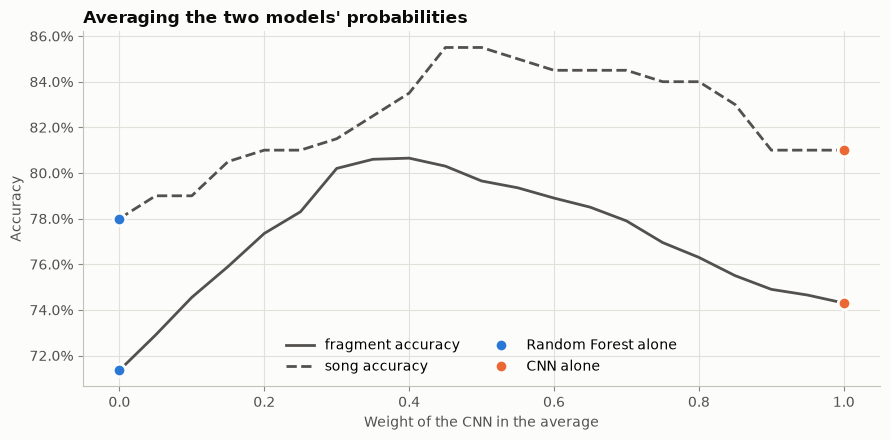

Best weight on this holdout: 0.40 | fragment accuracy 0.8065 | song accuracy 0.8350


In [9]:
weights = np.linspace(0, 1, 21)
ensemble = []
for w in weights:
    mixed = w * cnn_proba + (1 - w) * rf_proba
    mixed_songs = pd.DataFrame(mixed, columns=labels).groupby(df["song_id"].values).mean().loc[songs.index]
    ensemble.append(
        {
            "weight": w,
            "fragment": accuracy_score(df["label"], labels[mixed.argmax(axis=1)]),
            "song": accuracy_score(songs, mixed_songs.idxmax(axis=1)),
        }
    )
ensemble = pd.DataFrame(ensemble).set_index("weight")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(ensemble.index, ensemble["fragment"], color=INK_SECONDARY, label="fragment accuracy")
ax.plot(ensemble.index, ensemble["song"], color=INK_SECONDARY, linestyle="--", label="song accuracy")
for name, w in [("Random Forest", 0.0), ("CNN", 1.0)]:
    ax.plot([w, w], ensemble.loc[w, ["fragment", "song"]], linestyle="none", marker="o", markersize=9,
            color=COLORS[name], markeredgecolor="#fcfcfb", markeredgewidth=2, label=f"{name} alone")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Weight of the CNN in the average")
ax.set_ylabel("Accuracy")
ax.set_title("Averaging the two models' probabilities")
ax.legend(loc="lower center", ncols=2)
plt.tight_layout()
plt.show()

best = ensemble["fragment"].idxmax()
print(f"Best weight on this holdout: {best:.2f} | fragment accuracy {ensemble.loc[best, 'fragment']:.4f} | song accuracy {ensemble.loc[best, 'song']:.4f}")

## Clips where only one model is right

Spectrograms from the holdout set where the models disagree, picked at random.

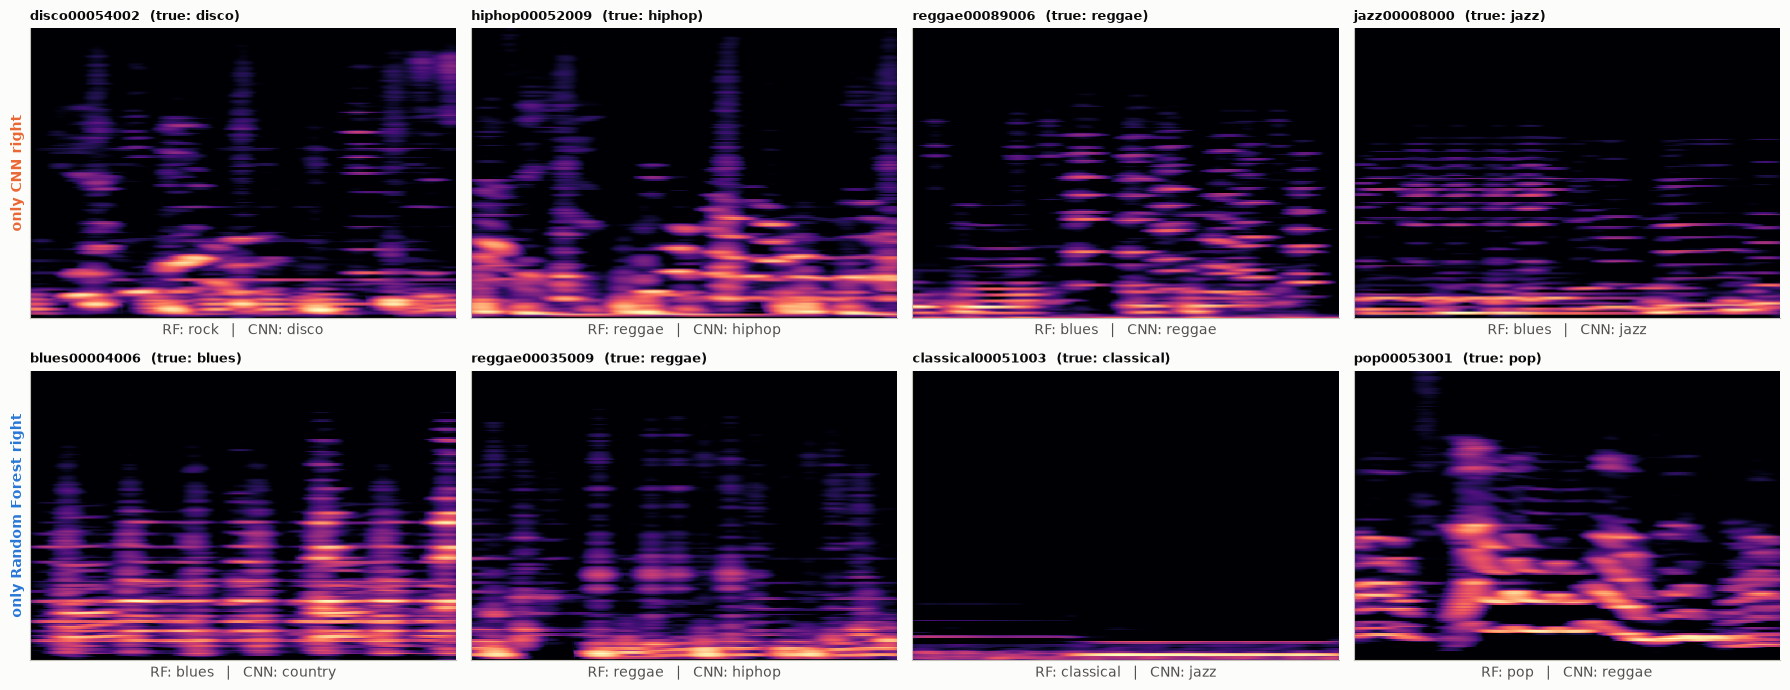

In [10]:
rng = np.random.default_rng(0)
groups = [("only CNN right", df[df["cnn_correct"] & ~df["rf_correct"]]), ("only Random Forest right", df[df["rf_correct"] & ~df["cnn_correct"]])]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for row, (title, subset) in zip(axes, groups):
    picks = subset.iloc[rng.choice(len(subset), size=min(4, len(subset)), replace=False)] if len(subset) else subset
    for ax, (_, clip) in zip(row, picks.iterrows()):
        ax.imshow(cnn_module.load_spectrogram_png(clip["path"]), aspect="auto")
        ax.set_title(f"{clip['filename']}  (true: {clip['label']})", fontsize=9, loc="left")
        ax.set_xlabel(f"RF: {clip['rf_pred']}   |   CNN: {clip['cnn_pred']}", color=INK_SECONDARY)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    row[0].set_ylabel(title, color=COLORS["CNN" if title.startswith("only CNN") else "Random Forest"], fontweight="bold")
plt.tight_layout()
plt.show()